<a href="https://colab.research.google.com/github/Echida/cms-dimuon-activation-ablation/blob/main/cms_dimuon_activation_ablation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("https://opendata.cern/record/700/files/MuRun2010B.csv")

In [ ]:
df.shape

(100000, 21)

In [ ]:
df.head()

,Run,Event,Type1,E1,px1,py1,pz1,pt1,eta1,phi1,...,Type2,E2,px2,py2,pz2,pt2,eta2,phi2,Q2,M
0,146436,90830792,G,19.17120,3.817130,9.04323,-16.46730,9.81583,-1.289420,1.171390,...,T,5.43984,-0.362592,2.626990,-4.748490,2.65189,-1.345870,1.707960,1,2.73205
1,146436,90862225,G,12.94350,5.125790,-3.98369,-11.19730,6.49180,-1.313350,-0.660674,...,G,11.86360,4.789840,-6.262220,-8.864340,7.88403,-0.966622,-0.917841,1,3.10256
2,146436,90644850,G,12.39990,-0.849742,9.40110,8.04015,9.43943,0.772580,1.660940,...,G,8.55532,-4.851550,6.976960,-0.983229,8.49797,-0.115445,2.178410,-1,9.41149
3,146436,90678594,G,17.81320,-1.959590,2.80531,17.48110,3.42195,2.333500,2.180530,...,G,9.42174,4.365230,0.168017,8.347130,4.36846,1.403000,0.038471,1,7.74702
4,146436,90686690,G,7.95664,7.097000,-1.31646,3.34613,7.21806,0.448399,-0.183411,...,T,5.44467,-1.341760,1.386470,5.090250,1.92941,1.697380,2.339810,-1,8.67727


In [ ]:
import matplotlib.pyplot as plt

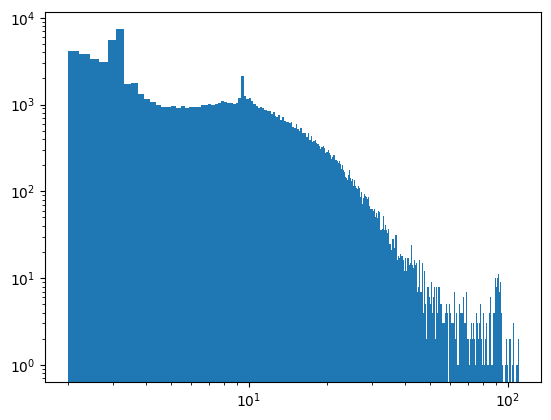

In [ ]:
plt.hist(df["M"], bins=500)
plt.xscale("log")
plt.yscale("log")
plt.show()


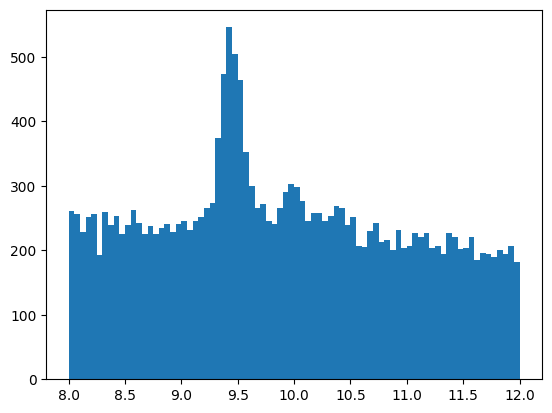

In [ ]:
plt.hist(df["M"], bins=80, range=(8, 12))

plt.show()


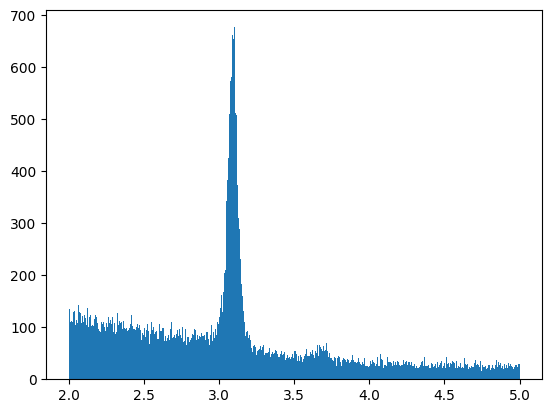

In [ ]:
plt.hist(df["M"], bins=500, range=(2, 5))

plt.show()

In [3]:
df.columns = df.columns.str.strip()
Y=df["M"]
X=df[["E1","E2","px1","px2","py1","py2","pz1","pz2"]]
print(X.shape)
print(Y.shape)

(100000, 8)
(100000,)


In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error

In [5]:
X_egitim, X_test, Y_egitim, Y_test=train_test_split(X,Y,test_size=0.2,random_state=0)
print(X_egitim.shape)
print(X_test.shape)

(80000, 8)
(20000, 8)


In [6]:
olcekleyici=StandardScaler()
X_egitim=olcekleyici.fit_transform(X_egitim)
X_test=olcekleyici.transform(X_test)
print(X_egitim.mean(axis=0).round(2))
print(X_egitim.std(axis=0).round(2))

[-0. -0.  0.  0. -0. -0.  0.  0.]
[1. 1. 1. 1. 1. 1. 1. 1.]


In [7]:
model=MLPRegressor(hidden_layer_sizes=(100, 100),activation="relu",max_iter=200,random_state=0)
model.fit(X_egitim,Y_egitim)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


MLPRegressor(hidden_layer_sizes=(100, 100), random_state=0)

In [8]:
tahmin=model.predict(X_test)
r2=r2_score(Y_test,tahmin)
print(r2)


0.8961807692975124


In [9]:
bolge1 = (Y_test > 2) & (Y_test < 5)
rmse1 = np.sqrt(mean_squared_error(Y_test[bolge1], tahmin[bolge1]))
print(rmse1)
bolge2 = (Y_test > 8) & (Y_test < 12)
rmse2 = np.sqrt(mean_squared_error(Y_test[bolge2], tahmin[bolge2]))
print(rmse2)

3.85927406896581
2.108224398531755


In [ ]:
def deney(tohum, aktivasyon, noron, oran=0.001, tur=200, sabir=10):




  X_egitim, X_test, Y_egitim, Y_test=train_test_split(X,Y,test_size=0.2,random_state=tohum)
  olcekleyici=StandardScaler()
  X_egitim=olcekleyici.fit_transform(X_egitim)
  X_test=olcekleyici.transform(X_test)
  model=MLPRegressor(hidden_layer_sizes=(noron,noron), activation=aktivasyon, learning_rate_init=oran, max_iter=tur, n_iter_no_change=sabir, random_state=tohum)
  model.fit(X_egitim,Y_egitim)
  tahmin=model.predict(X_test)
  r2=r2_score(Y_test,tahmin)
  bolge1 = (Y_test > 2) & (Y_test < 5)
  rmse1 = np.sqrt(mean_squared_error(Y_test[bolge1], tahmin[bolge1]))
  bolge2 = (Y_test > 8) & (Y_test < 12)
  rmse2 = np.sqrt(mean_squared_error(Y_test[bolge2], tahmin[bolge2]))
  return r2, rmse1, rmse2

In [ ]:
print(deney(0, "relu", 100))

(0.9327445068386143, np.float64(3.15613971907648), np.float64(1.9451835868351814))


In [ ]:
sonuclar = []
for aktivasyon in ["relu", "identity"]:
  for tohum in [0, 1, 2, 3, 4]:
    r2, rmse1, rmse2 = deney(tohum, aktivasyon, 100)
    sonuclar.append([aktivasyon, tohum, r2, rmse1, rmse2])
    print(aktivasyon, tohum, r2, rmse1, rmse2)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


KeyboardInterrupt: 

In [ ]:
sonuclar2 = []
for noron in [100,200,400]:
  for aktivasyon in ["relu", "identity"]:
    for tohum in [0, 1, 2]:
      r2, rmse1, rmse2 = deney(tohum, aktivasyon, noron)
      sonuclar2.append([noron, aktivasyon, tohum, r2, rmse1, rmse2])
      print(noron, aktivasyon, tohum, r2, rmse1, rmse2)

100 relu 0 0.9327445068386143 3.15613971907648 1.9451835868351814
100 relu 1 0.959412904011815 1.4793010705812728 1.145941732097139
100 relu 2 0.9699955805593794 1.6767352255115855 1.7529717218748284
100 identity 0 -0.005854315683131217 5.6957921139487615 3.509076472201169
100 identity 1 0.07795886892189707 7.81331243733376 1.7339411429346907
100 identity 2 0.014458658390744228 8.767304261896934 4.043841917191569
200 relu 0 0.8263313664441133 4.78611975989054 4.9121348853235975
200 relu 1 0.9724232163863595 1.4068329952747758 0.882521559777438
200 relu 2 0.9455554294675625 1.2605048071347136 4.108773498787935
200 identity 0 0.0373633161557696 8.296097763652407 2.913419789464448
200 identity 1 0.0854202074259709 7.526924352745337 1.737318748287985
200 identity 2 0.017351262006433554 8.421138957348306 4.158319844646756
400 relu 0 0.9510443455056822 1.4504837001614939 1.3981461442108558
400 relu 1 0.9812796077967749 1.0202344372694365 0.6618170450453009
400 relu 2 0.930125201016211 1.4643

In [ ]:
sonuclar3 = []
for noron in [100, 200, 400]:
    for tohum in [0, 1, 2]:
        r2, rmse1, rmse2 = deney(tohum, "relu", noron, oran=0.0003, tur=600, sabir=50)
        sonuclar3.append([noron, tohum, r2, rmse1, rmse2])
        print(noron, tohum, r2, rmse1, rmse2)

100 0 0.9814015428992603 1.1003571553550986 0.8243914729475361
100 1 0.9829620227462613 0.8314730889391634 0.8017633371587816
100 2 0.9842178676168809 1.539488071789239 0.8488098257395127
200 0 0.986602837541355 1.26235392301723 0.6853122658257299
200 1 0.9867099886515942 0.7421986975629077 0.584042793323199
200 2 0.9822890531833606 1.0381821257780712 2.037359342645295
400 0 0.9906238575198365 1.1389547161008027 0.6584247029279418
400 1 0.9911581513859156 0.5745251965527437 0.46496666924735913
400 2 0.9531905587037465 0.5724870494545935 4.613004695159736


In [10]:
pd.set_option("display.max_columns", None)

X_egitim, X_test, Y_egitim, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
olcekleyici = StandardScaler()
X_egitim_s = olcekleyici.fit_transform(X_egitim)
X_test_s = olcekleyici.transform(X_test)
model = MLPRegressor(hidden_layer_sizes=(400, 400), random_state=2)
model.fit(X_egitim_s, Y_egitim)
tahmin = model.predict(X_test_s)

tablo = X_test.copy()
tablo["M_gercek"] = Y_test
tablo["M_tahmin"] = tahmin
tablo["hata"] = (tablo["M_tahmin"] - tablo["M_gercek"]).abs()
bolge = tablo[(tablo["M_gercek"] > 8) & (tablo["M_gercek"] < 12)]
sirali = bolge.sort_values("hata", ascending=False)

print(len(bolge))
print(np.sqrt((bolge["hata"] ** 2).mean()))
print(sirali.head(5))
print(np.sqrt((sirali["hata"].iloc[5:] ** 2).mean()))
print(X_egitim.describe().loc[["mean", "max"]])

3933
5.165291953151895
              E1        E2       px1       px2        py1        py2  \
318    3384.4300   5.67306  593.6610  0.615739  385.34400   0.889774   
4241   1366.6500  11.35870  272.5660  1.799360  -42.46870  -1.003540   
95924   105.8420  12.02630   18.6208  5.128070  -22.64810  -3.819080   
63611    22.9690  31.51280  -11.6530 -3.923600   14.87520  20.817300   
4500     11.2934  73.71640   -1.8534  9.439950    1.19299  25.593100   

             pz1       pz2  M_gercek    M_tahmin        hata  
318    3309.5900   5.56791  11.32530  330.913776  319.588476  
4241  -1338.5200 -11.16970   8.86914  -25.294170   34.163310  
95924   101.6990  10.18520  10.49590    0.685220    9.810680  
63611   -13.0577 -23.33010  11.29700    5.165740    6.131260  
4500     11.0757  68.48340  11.04370   16.244588    5.200888  
0.6114510381926722
              E1          E2         px1         px2         py1          py2  \
mean    17.57558     9.21981   -0.068024   -0.017604   -0.189712  

In [11]:
def egit_ve_tahmin(aktivasyon, oran, tur, sabir):
    X_egitim, X_test, Y_egitim, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)
    olcekleyici = StandardScaler()
    X_egitim_s = olcekleyici.fit_transform(X_egitim)
    X_test_s = olcekleyici.transform(X_test)
    model = MLPRegressor(hidden_layer_sizes=(100, 100), activation=aktivasyon, learning_rate_init=oran, max_iter=tur, n_iter_no_change=sabir, random_state=0)
    model.fit(X_egitim_s, Y_egitim)
    return Y_test, model.predict(X_test_s)

Y_test, tahmin_relu = egit_ve_tahmin("relu", 0.0003, 600, 50)
_, tahmin_id = egit_ve_tahmin("identity", 0.001, 200, 10)

z = (Y_test > 80) & (Y_test < 100)
print(z.sum())
for ad, t in [("relu", tahmin_relu), ("identity", tahmin_id)]:
    rmse_z = np.sqrt(((t[z] - Y_test[z]) ** 2).mean())
    print(ad, rmse_z, rmse_z / 91.19 * 100)

89
relu 7.337060741171317 8.045904968934442
identity 75.35368338594063 82.63371354966623


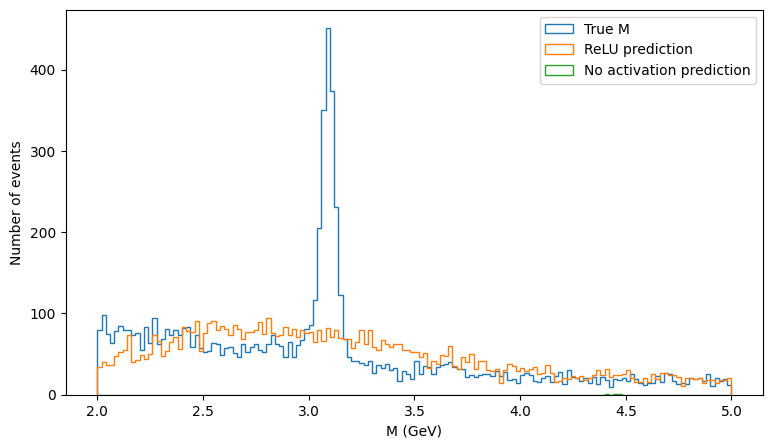

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.hist(Y_test, bins=150, range=(2, 5), histtype="step", label="True M")
plt.hist(tahmin_relu, bins=150, range=(2, 5), histtype="step", label="ReLU prediction")
plt.hist(tahmin_id, bins=150, range=(2, 5), histtype="step", label="No activation prediction")
plt.xlabel("M (GeV)")
plt.ylabel("Number of events")
plt.legend()
plt.savefig("tahmin_histogram.png", dpi=150)
plt.show()

100 1.1003571553550986
400 1.1389547161008027


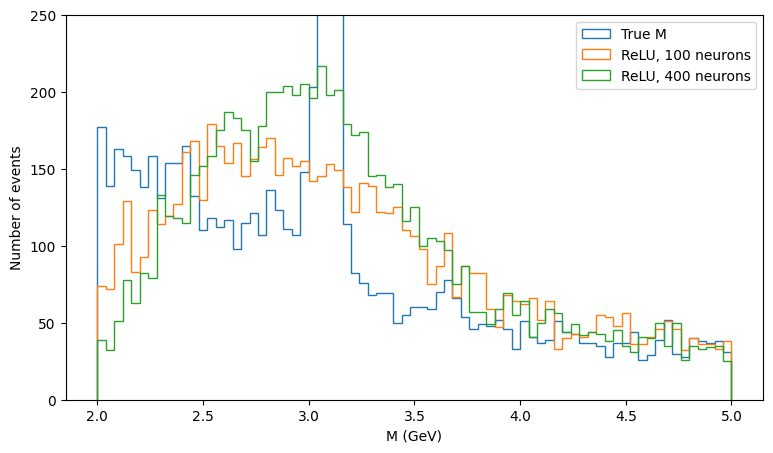

In [14]:
def egit_ve_tahmin(aktivasyon, oran, tur, sabir, noron=100):
    X_egitim, X_test, Y_egitim, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)
    olcekleyici = StandardScaler()
    X_egitim_s = olcekleyici.fit_transform(X_egitim)
    X_test_s = olcekleyici.transform(X_test)
    model = MLPRegressor(hidden_layer_sizes=(noron, noron), activation=aktivasyon, learning_rate_init=oran, max_iter=tur, n_iter_no_change=sabir, random_state=0)
    model.fit(X_egitim_s, Y_egitim)
    return Y_test, model.predict(X_test_s)

Y_test, tahmin_relu400 = egit_ve_tahmin("relu", 0.0003, 600, 50, noron=400)

b = (Y_test > 2) & (Y_test < 5)
for ad, t in [("100", tahmin_relu), ("400", tahmin_relu400)]:
    print(ad, np.sqrt(((t[b] - Y_test[b]) ** 2).mean()))

plt.figure(figsize=(9, 5))
plt.hist(Y_test, bins=75, range=(2, 5), histtype="step", label="True M")
plt.hist(tahmin_relu, bins=75, range=(2, 5), histtype="step", label="ReLU, 100 neurons")
plt.hist(tahmin_relu400, bins=75, range=(2, 5), histtype="step", label="ReLU, 400 neurons")
plt.ylim(0, 250)
plt.xlabel("M (GeV)")
plt.ylabel("Number of events")
plt.legend()
plt.savefig("kambur_100_400.png", dpi=150)
plt.show()